# Examen Final - Minería de Datos 1
## Grupo #2 - Clusterización de jefaturas de la CCSS
### Informe técnico con la metodología CRISP-DM

| | |
|---|---|
| Curso | Minería de Datos 1 - Big Data BD-152, Colegio Universitario de Cartago |
| Profesor | Ronald Córdoba Vega |
| Metodología | CRISP-DM (Cross Industry Standard Process for Data Mining) |
| Conjunto de datos | MD1_CL_jefaturas_export_19112026.csv |
| Fuente | Datos abiertos de la Caja Costarricense de Seguro Social (CCSS), fecha de corte 12/10/2026 |

Integrantes:

| Cédula | Nombre |
|---|---|
| 305640170 | Derek Barrantes Torres |
| 207260607 | Claret Charlotte Rodríguez Jiménez |
| 305630770 | Stephanie Cristina Rodríguez Cortés |
| 303590844 | Mauricio Ortiz Coronado |
| 304920721 | Byron Andrés Pérez Aguilar |

Estructura del informe:

| Sección | Fase CRISP-DM | Contenido |
|---|---|---|
| 1 | Comprensión del negocio | Contexto institucional, objetivos, evaluación de la situación y plan del proyecto |
| 2 | Comprensión de los datos | Recolección, descripción, exploración y verificación de la calidad de los datos |
| 3 | Preparación de los datos | Selección, formateo, limpieza, construcción de variables por unidad, transformación y estandarización |
| 4 | Modelado | Selección de la técnica, prueba de distintas cantidades de grupos y construcción del modelo |
| 5 | Evaluación | Métricas de calidad, perfil de cada grupo y contraste con los criterios de éxito y las hipótesis |
| 6 | Implementación | Predicción para unidades nuevas, hallazgos de negocio y recomendaciones |

El archivo original de datos no se modifica en ningún momento: los datos limpios se guardan como un
archivo nuevo.

# Fase 1. Comprensión del negocio

La comprensión del negocio es probablemente la fase más importante de CRISP-DM: consiste en entender
los objetivos y requisitos del proyecto desde la perspectiva de la institución para convertirlos en
objetivos técnicos de minería de datos y en un plan de trabajo. Sin esta comprensión, ningún
algoritmo, por sofisticado que sea, produce resultados confiables ni interpretables.

La fase se desarrolla mediante sus cuatro tareas: determinar los objetivos del negocio, evaluar la
situación, determinar los objetivos de minería de datos y producir el plan del proyecto.

## 1.1 Contexto institucional

La Caja Costarricense de Seguro Social (CCSS) es la institución responsable de la seguridad
social en Costa Rica. Sus funciones se organizan en tres grandes ámbitos, que se reflejan
directamente en las unidades presentes en el conjunto de datos:

Servicios de salud: hospitales nacionales, regionales y periféricos; áreas de salud del primer nivel de atención; centros especializados y laboratorios.

Pensiones: administración de los regímenes de pensiones y de las prestaciones sociales.

Gestión financiera y recaudación: sucursales distribuidas en todo el país, encargadas de la afiliación, el cobro y la inspección.

Estas funciones se dirigen desde un nivel central (Junta Directiva, Presidencia Ejecutiva y
gerencias como la Médica, Financiera, de Pensiones, Administrativa, de Logística y de
Infraestructura y Tecnologías) y se coordinan mediante direcciones regionales.

Cada una de estas unidades cuenta con puestos de jefatura: personas responsables de dirigir
servicios, áreas o subáreas. La cantidad y el tipo de jefaturas de una unidad reflejan su tamaño,
su complejidad y la variedad de servicios que presta. Un hospital nacional requiere jefaturas
médicas, de enfermería, de laboratorio, de farmacia y administrativas, mientras que una sucursal
suele tener una única jefatura administrativa.

## 1.2 Determinación de los objetivos del negocio

### Problema del negocio

La CCSS registra 1,949 jefaturas distribuidas en 284 unidades organizacionales con estructuras
muy distintas entre sí. Esta diversidad dificulta comparar unidades, planificar la dotación de
puestos de jefatura o identificar unidades cuya estructura se aparta de lo esperado para su tipo.
Las clasificaciones administrativas de las unidades (por ejemplo, hospital nacional o área de
salud) no necesariamente reflejan cómo está compuesta realmente su estructura de jefaturas.

### Preguntas de negocio

1. ¿Qué perfiles de unidades existen según el tamaño, la diversidad y la concentración de sus jefaturas?
2. ¿Qué unidades presentan estructuras atípicas en comparación con las demás?
3. ¿Los perfiles encontrados coinciden con los tipos de unidad conocidos (hospitales, áreas de salud,
   sucursales, oficinas centrales) o revelan agrupaciones nuevas?
4. Dada una unidad nueva o reorganizada, ¿a qué perfil pertenecería según su estructura de jefaturas?

### ¿Por qué utilizar minería de datos?

Con 284 unidades y 159 puestos distintos, una clasificación manual sería lenta, subjetiva y difícil
de repetir. Las técnicas de agrupamiento no supervisado permiten descubrir los perfiles a partir
de los propios datos, sin definir los grupos de antemano, y medir objetivamente qué tan similares
son las unidades de un mismo grupo y qué tan distintas son de las demás.

### Criterios de éxito del negocio (cualitativos)

Los perfiles obtenidos son interpretables: cada grupo puede describirse en lenguaje de negocio (por ejemplo, "unidades unipersonales" u "hospitales de alta complejidad").

Los perfiles son coherentes con el conocimiento institucional: un conocedor de la CCSS reconocería las unidades de cada grupo como similares.

Los resultados permiten identificar unidades atípicas y responder las preguntas de negocio.

El modelo permite asignar una unidad nueva a uno de los perfiles.

## 1.3 Evaluación de la situación

### Inventario de recursos

| Recurso | Detalle |
|---|---|
| Datos | Un archivo CSV con 1,949 registros y 6 variables, de acceso público |
| Personas | Equipo de 5 integrantes del Grupo 2 |
| Software | Python 3, Jupyter Notebook, pandas, NumPy, Matplotlib, Seaborn, SciPy y scikit-learn |
| Control de versiones | Repositorio en GitHub, con el trabajo dividido por fases |
| Conocimiento previo | Material del curso sobre CRISP-DM, análisis exploratorio y técnicas de agrupamiento |

### Requisitos del proyecto

Aplicar la metodología CRISP-DM de forma explícita.

Realizar una exploración exhaustiva de estadísticas descriptivas para identificar comportamientos, distribuciones y anomalías.

Aplicar técnicas de segmentación y agrupamiento, evaluar la calidad de los conglomerados y realizar una predicción.

Entregables: informe técnico en Word, informe técnico en HTML generado desde Jupyter (con código, ejecución e interpretación) y presentación en PowerPoint. No se aceptan trabajos en PDF.

Fecha de entrega: 9 de diciembre de 2026, antes de las 6:00 p. m., con defensa el mismo día.

### Supuestos

El archivo representa la totalidad de las jefaturas registradas a la fecha de corte (12/10/2026).

Cada registro corresponde a una persona distinta, identificada por su cédula.

El código y el nombre de la unidad identifican de forma única a cada unidad organizacional.

La columna Puesto refleja el puesto registrado para cada persona en la fuente oficial.

### Restricciones

No existen variables numéricas directas: todas las variables son identificadores, códigos o texto categórico. Las variables para el modelado deben construirse a partir de los datos.

Una sola fecha de corte: no es posible analizar la evolución en el tiempo.

Información no disponible: el archivo no incluye salarios, cantidad de personal a cargo, presupuesto ni ubicación geográfica de las unidades.

Alta cardinalidad: 159 puestos y 284 unidades, muchas de ellas con un solo registro.

### Riesgos y planes de contingencia

| Riesgo | Plan de contingencia |
|---|---|
| Errores de codificación al leer el archivo (tildes y ñ dañadas) | Verificar la codificación del archivo en bruto antes de cargarlo |
| Valores inválidos o con formato irregular | Verificación de la calidad en la sección 2.4 y limpieza documentada en la sección 3 |
| Variables de tamaño redundantes que dominen el cálculo de distancias | Análisis de correlación y selección de variables no redundantes |
| Distribuciones muy asimétricas | Transformación logarítmica y estandarización |
| Conglomerados difíciles de interpretar | Comparar varias cantidades de grupos con métricas internas y criterio de negocio |
| Conflictos al trabajar en equipo sobre los mismos archivos | División del trabajo por fases y uso de control de versiones en GitHub |

### Terminología

| Término | Significado en este proyecto |
|---|---|
| UP (Unidad de procedencia) | Unidad organizacional de la CCSS a la que pertenece la jefatura |
| Jefatura | Registro de una persona en un puesto de dirección o coordinación dentro de una unidad |
| Área de Salud | Unidad del primer nivel de atención en salud |
| Sucursal | Unidad encargada de afiliación, recaudación e inspección en una región |
| Conglomerado (cluster) | Grupo de unidades con características similares |
| Entropía de puestos | Medida de la diversidad de puestos de una unidad: vale 0 si todos sus puestos son iguales y aumenta cuanto más variados y equilibrados son |
| Silhouette | Métrica de -1 a 1 que indica qué tan bien separado está cada elemento de los otros grupos |

### Costos y beneficios

El costo del proyecto es bajo: los datos son públicos y todas las herramientas utilizadas son de
software libre. El beneficio potencial es contar con una tipología objetiva de unidades que
apoye la planificación de jefaturas, la comparación entre unidades similares y la detección de
estructuras atípicas que merezcan revisión.

## 1.4 Determinación de los objetivos de minería de datos

Los objetivos del negocio se traducen en los siguientes objetivos técnicos:

| Objetivo del negocio | Objetivo de minería de datos |
|---|---|
| Identificar perfiles de unidades | Aplicar un algoritmo de agrupamiento no supervisado sobre indicadores construidos por unidad |
| Describir cada perfil | Caracterizar cada conglomerado con estadísticas descriptivas de sus variables |
| Identificar unidades atípicas | Detectar valores extremos y conglomerados de tamaño reducido |
| Asignar unidades nuevas a un perfil | Usar el modelo entrenado para predecir el conglomerado de una unidad nueva |

Como el conjunto de datos no contiene variables numéricas directas, el análisis se realiza a nivel
de unidad organizacional. Para cada unidad se construirán indicadores de:

Tamaño: cantidad total de jefaturas.

Diversidad: cantidad de puestos distintos y entropía de la distribución de puestos.

Concentración: proporción de jefaturas que ocupa el puesto más frecuente.

### Criterios de éxito de minería de datos (cuantitativos)

Silhouette Score mayor a 0.5, lo que indica una estructura de grupos razonablemente definida.

Índice de Davies-Bouldin menor a 1, lo que indica grupos compactos y separados.

Selección de la cantidad de grupos respaldada por el método del codo y el índice de Calinski-Harabasz.

Ningún conglomerado de tamaño muy reducido sin una justificación de negocio.

Capacidad del modelo para asignar un conglomerado a una unidad nueva.

## 1.5 Plan del proyecto

| Fase CRISP-DM | Actividades | Técnicas y herramientas | Producto |
|---|---|---|---|
| 1. Comprensión del negocio | Contexto, objetivos, situación y plan | Análisis documental | Sección 1 |
| 2. Comprensión de los datos | Recolección, descripción, exploración y verificación de calidad | pandas, estadística descriptiva, gráficos | Sección 2 |
| 3. Preparación de los datos | Limpieza, selección, construcción de indicadores por unidad, transformación y estandarización | pandas, NumPy, transformación log1p, StandardScaler | Sección 3 |
| 4. Modelado | Selección de la técnica, prueba de 2 a 10 grupos y construcción del modelo | K-Means (scikit-learn) | Sección 4 |
| 5. Evaluación | Métricas internas, perfil de cada grupo y contraste con los criterios de éxito | Codo, Silhouette, Calinski-Harabasz, Davies-Bouldin | Sección 5 |
| 6. Implementación | Predicción para unidades nuevas, hallazgos y recomendaciones | predict del modelo entrenado | Sección 6, informe Word y presentación |

### Evaluación inicial de técnicas

Se consideraron técnicas de agrupamiento como K-Means, el agrupamiento jerárquico, DBSCAN
y K-Modes (para datos categóricos). Se seleccionó K-Means aplicado sobre indicadores
numéricos construidos por unidad porque:

Permite predecir el grupo de una unidad nueva, requisito del examen; el agrupamiento jerárquico y DBSCAN no ofrecen esta funcionalidad de forma directa.

Al construir indicadores numéricos por unidad se evita aplicar distancias sobre categorías de alta cardinalidad, problema que tendría K-Means con variables dummies.

Cuenta con métricas de evaluación estándar y produce centroides fáciles de interpretar.

# Fase 2. Comprensión de los datos

Esta fase busca establecer un primer contacto con los datos, familiarizarse con ellos, identificar
su calidad y encontrar las relaciones más evidentes que permitan formular las primeras hipótesis.
Se desarrolla mediante sus cuatro tareas: recolección de los datos iniciales, descripción,
exploración y verificación de la calidad de los datos.

## 2.1 Recolección de los datos iniciales

| Aspecto | Detalle |
|---|---|
| Datos adquiridos | MD1_CL_jefaturas_export_19112026.csv |
| Origen | Datos abiertos de la CCSS, proporcionados por el profesor para el examen |
| Localización en el proyecto | data/raw/ (copia original, nunca se modifica) |
| Fecha de corte | 12/10/2026 |
| Formato | Texto delimitado (CSV) |

### Librerías

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

### Carga de los datos

El archivo se carga con encoding="latin-1" porque, con la codificación por defecto de pandas
(UTF-8), las tildes y la ñ no se leen correctamente.

In [131]:
ruta_archivo = "../data/raw/MD1_CL_jefaturas_export_19112026.csv"

df = pd.read_csv(
    ruta_archivo,
    sep=";",
    encoding="latin-1"
)

df.head()

,Cedula,Nombre,Unidad de procedencia (UP),Detalle de UP,Puesto,Fecha de actualización
0,107790683,KARLA SOLANO DURAN,1100,Gerencia General,Jefe Despacho Gerencia General,2026-10-12 00:00:00
1,113570358,JOSE LUIS ROJAS HENRIQUEZ,1101,Junta Directiva,Jefe Subárea de Sede,2026-10-12 00:00:00
2,113750446,MARIA BEATRIZ GUZMAN MEZA,1101,Junta Directiva,Jefe Área de Sede,2026-10-12 00:00:00
3,107960815,LAURA MARIA AVILA BOLAÑOS,1102,Presidencia Ejecutiva,Asesor Coordinar Presidencia Ejecutiva,2026-10-12 00:00:00
4,108340101,ALEXANDER SOLIS ABARCA,1103,Gerencia Financiera,Jefe Área de Sede,2026-10-12 00:00:00


## 2.2 Descripción de los datos

En esta tarea se establece el volumen de los datos (cantidad de registros y campos), la
identificación y el significado de cada campo y su formato inicial.

### Vista inicial del Dataset

In [132]:
print(f"Número de registros: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")

Número de registros: 1,949
Número de variables: 6


In [133]:
df.columns.tolist()

['Cedula',
 'Nombre',
 'Unidad de procedencia (UP)',
 'Detalle de UP',
 'Puesto',
 'Fecha de actualización']

### Estructura y tipo de datos

In [134]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1949 entries, 0 to 1948
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Cedula                      1949 non-null   int64
 1   Nombre                      1949 non-null   str  
 2   Unidad de procedencia (UP)  1949 non-null   int64
 3   Detalle de UP               1949 non-null   str  
 4   Puesto                      1949 non-null   str  
 5   Fecha de actualización      1949 non-null   str  
dtypes: int64(2), str(4)
memory usage: 91.5 KB


In [135]:
resumen_variables = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores no nulos": df.notna().sum(),
    "Valores nulos": df.isna().sum(),
    "% Nulos": (df.isna().mean() * 100).round(2),
    "Valores únicos": df.nunique(dropna=False)
})

resumen_variables

,Tipo de dato,Valores no nulos,Valores nulos,% Nulos,Valores únicos
Cedula,int64,1949,0,0.0,1949
Nombre,str,1949,0,0.0,1948
Unidad de procedencia (UP),int64,1949,0,0.0,284
Detalle de UP,str,1949,0,0.0,284
Puesto,str,1949,0,0.0,159
Fecha de actualización,str,1949,0,0.0,1


### Interpretación de la estructura y completitud de los datos

El conjunto de datos contiene 1,949 registros y 6 variables. No se
identificaron valores nulos en ninguna de las columnas, por lo que, en
principio, no será necesario aplicar técnicas de imputación.

La variable Cedula presenta 1,949 valores únicos, lo cual indica que cada
identificador aparece una sola vez en el conjunto de datos. Sin embargo,
Nombre presenta 1,948 valores únicos, por lo que existe al menos un nombre
repetido asociado potencialmente con identificadores diferentes. Este caso
debe revisarse antes de determinar si se trata de una inconsistencia o de
personas distintas que comparten el mismo nombre.

Las variables Unidad de procedencia (UP) y Detalle de UP presentan 284
valores únicos cada una. Esto sugiere una posible correspondencia entre el
código y el nombre de cada unidad organizacional, aunque dicha relación debe
ser validada explícitamente.

La variable Puesto contiene 159 categorías únicas, lo que evidencia una
diversidad considerable de puestos de jefatura. Será necesario evaluar la
consistencia de estas categorías y determinar si existen variantes de
escritura o categorías que puedan agruparse en familias de puestos.

Finalmente, Fecha de actualización contiene un único valor para todos los
registros. Por lo tanto, representa la fecha de corte del conjunto de datos,
pero no aporta variabilidad para el modelado de clusterización. Esta variable
se conservará como información descriptiva, pero será excluida de las
características utilizadas para calcular los conglomerados.

### Diccionario de variables

| Variable | Descripción | Tipo real | Uso en el análisis |
|---|---|---|---|
| Cedula | Identificación de la persona | Identificador | Solo para conteos; no entra al modelo |
| Nombre | Nombre completo de la persona | Identificador | No entra al modelo |
| Unidad de procedencia (UP) | Código numérico de la unidad | Código categórico | Llave de agrupación por unidad |
| Detalle de UP | Nombre de la unidad | Categórica (284 valores) | Llave de agrupación por unidad |
| Puesto | Puesto registrado de la persona | Categórica (159 valores) | Base para construir indicadores |
| Fecha de actualización | Fecha de corte del archivo | Fecha (valor único) | Descriptiva; no entra al modelo |

Aunque pandas interpreta Cedula y Unidad de procedencia (UP) como enteros (int64), ambas son
códigos: no representan cantidades y no tiene sentido calcular promedios o distancias sobre ellas.
El conjunto de datos no contiene ninguna variable numérica medible de forma directa; las variables
numéricas para el modelado deberán construirse a partir de los datos.

## 2.3 Exploración de los datos

El objetivo de esta tarea es encontrar la estructura general de los datos mediante tablas de
frecuencia, estadísticas descriptivas y gráficos de distribución. Primero se exploran los puestos y
los tipos de unidad; luego se analiza la distribución de jefaturas por unidad y la diversidad y
concentración de sus puestos.

### Análisis de los puestos

In [136]:
frecuencia_puestos = df["Puesto"].str.strip().value_counts()

print("Puestos distintos:", len(frecuencia_puestos))
print("Puestos con un solo registro:", (frecuencia_puestos == 1).sum())
print("Puestos con menos de 5 registros:", (frecuencia_puestos < 5).sum())
print(
    "Porcentaje de registros que cubren los 20 puestos más frecuentes:",
    round(frecuencia_puestos.head(20).sum() / len(df) * 100, 2), "%"
)

Puestos distintos: 159
Puestos con un solo registro: 50
Puestos con menos de 5 registros: 82
Porcentaje de registros que cubren los 20 puestos más frecuentes: 61.57 %


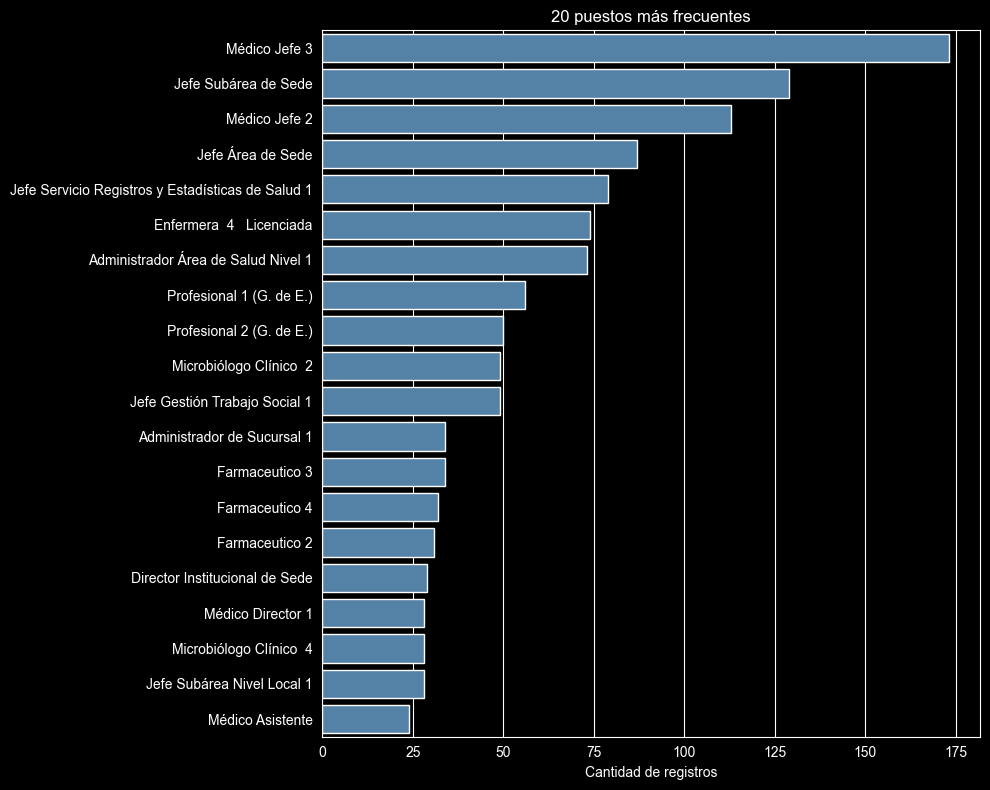

In [137]:
plt.figure(figsize=(10, 8))

sns.barplot(
    x=frecuencia_puestos.head(20).values,
    y=frecuencia_puestos.head(20).index,
    color="steelblue"
)

plt.title("20 puestos más frecuentes")
plt.xlabel("Cantidad de registros")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [138]:
terminos_jefatura = (
    r"Jefe|Director|Gerente|Administrador|Coordinador|Supervisor|"
    r"Subdirector|Sub-Administrador|Auditor|Asesor"
)

puesto_limpio = df["Puesto"].str.strip()
sin_termino_jefatura = (
    ~puesto_limpio.str.contains(terminos_jefatura)
    & (puesto_limpio != "#N/D")
)

print(
    "Registros cuyo puesto no contiene un término de jefatura:",
    sin_termino_jefatura.sum(),
    f"({sin_termino_jefatura.mean() * 100:.2f} %)"
)

puesto_limpio[sin_termino_jefatura].value_counts().head(20)

Registros cuyo puesto no contiene un término de jefatura: 645 (33.09 %)


Puesto
Enfermera  4   Licenciada    74
Profesional 1 (G. de E.)     56
Profesional 2 (G. de E.)     50
Microbiólogo Clínico  2      49
Farmaceutico 3               34
Farmaceutico 4               32
Farmaceutico 2               31
Microbiólogo Clínico  4      28
Médico Asistente             24
Profesional 4 (G. de E.)     20
Farmaceutico 1               20
Enfermera  1   Licenciada    18
Enfermera  5   Licenciada    17
Microbiólogo Clínico  3      16
Nutricionista 2              11
Farmaceutico 5               10
Microbiólogo Clínico  5      10
Enfermera  7   Licenciada     9
Nutricionista 4               9
Enfermera  6   Licenciada     8
Name: count, dtype: int64

### Interpretación del análisis de puestos

La variable Puesto tiene alta cardinalidad: 159 categorías para 1,949 registros. De ellas, 50 puestos aparecen una sola vez y 82 tienen menos de cinco registros. Los 20 puestos más frecuentes concentran el 61.57 % de los registros.

Los puestos más comunes son Médico Jefe 3 (173), Jefe Subárea de Sede (129), Médico Jefe 2 (113) y Jefe Área de Sede (87), lo que refleja el peso de los servicios de salud dentro de la institución.

Hallazgo relevante: 645 registros (33.09 %) tienen un puesto cuyo nombre no contiene un término de jefatura (por ejemplo Enfermera 4 Licenciada, Farmaceutico 3, Profesional 1 (G. de E.) o Médico Asistente, e incluso puestos operativos como Chofer 2 o Secretaria 3). En un archivo de jefaturas, esto sugiere que la columna registra el puesto en propiedad de la persona y no necesariamente la jefatura que ejerce (por ejemplo, jefaturas interinas o por recargo). Los registros se conservan, pero este punto debe considerarse al interpretar los resultados.

Debido a la alta cardinalidad, Puesto no se utilizará directamente como variable del modelo; en su lugar se construirán indicadores de diversidad y concentración por unidad.

### Tipos de unidad organizacional

A partir del nombre de la unidad se identifica, de forma exploratoria, el tipo de unidad al que
pertenece cada registro.

In [139]:
def tipo_unidad(nombre):
    if nombre.startswith("Hospital"):
        return "Hospital"
    if nombre.startswith("Área de Salud") or nombre.startswith("Area de Salud"):
        return "Área de Salud"
    if "Sucursal" in nombre or nombre.startswith("Agencia"):
        return "Sucursal / Agencia"
    inicios_oficinas = (
        "Dirección", "Gerencia", "Junta Directiva", "Presidencia", "Auditoria",
        "Área", "Area", "Subárea", "Centro para la Instruccion"
    )
    if nombre.startswith(inicios_oficinas):
        return "Oficinas centrales y regionales"
    return "Otros centros y servicios"

tipos = df["Detalle de UP"].apply(tipo_unidad)

resumen_tipos = pd.DataFrame({
    "Registros": tipos.value_counts(),
    "Unidades": df.groupby(tipos)["Detalle de UP"].nunique()
})
resumen_tipos.index.name = "Tipo de unidad"
resumen_tipos["% registros"] = (resumen_tipos["Registros"] / len(df) * 100).round(2)
resumen_tipos["Jefaturas promedio por unidad"] = (
    resumen_tipos["Registros"] / resumen_tipos["Unidades"]
).round(2)

resumen_tipos.sort_values("Registros", ascending=False)

,Registros,Unidades,% registros,Jefaturas promedio por unidad
Tipo de unidad,,,,
Hospital,744,28,38.17,26.57
Área de Salud,686,99,35.20,6.93
Oficinas centrales y regionales,337,58,17.29,5.81
Sucursal / Agencia,103,78,5.28,1.32
Otros centros y servicios,79,21,4.05,3.76


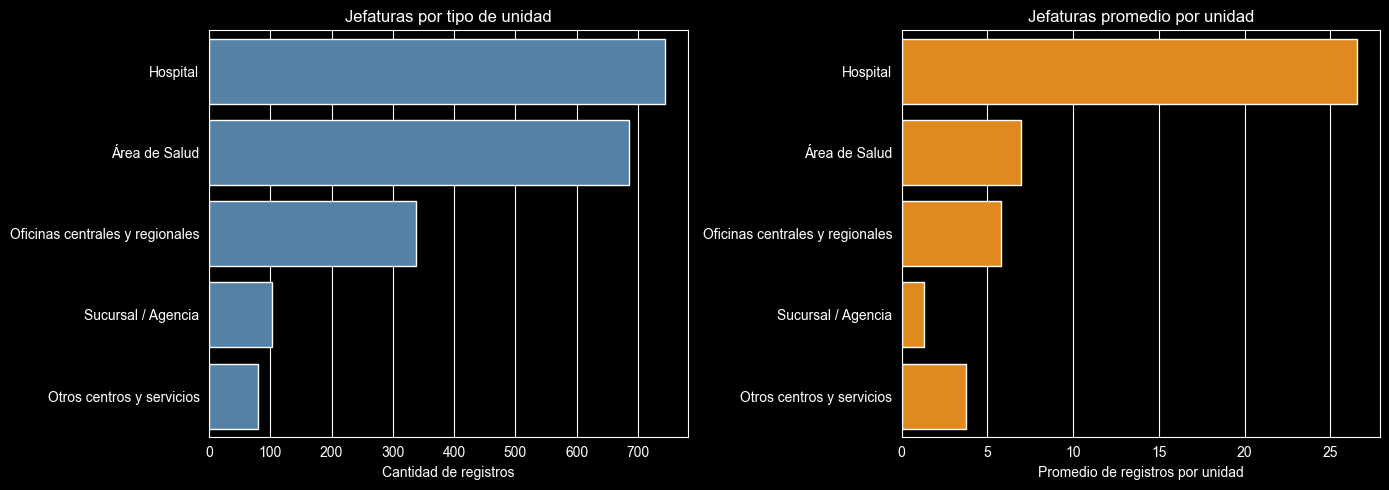

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

orden = resumen_tipos.sort_values("Registros", ascending=False).index

sns.barplot(
    x=resumen_tipos.loc[orden, "Registros"],
    y=orden,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Jefaturas por tipo de unidad")
axes[0].set_xlabel("Cantidad de registros")
axes[0].set_ylabel("")

sns.barplot(
    x=resumen_tipos.loc[orden, "Jefaturas promedio por unidad"],
    y=orden,
    color="darkorange",
    ax=axes[1]
)
axes[1].set_title("Jefaturas promedio por unidad")
axes[1].set_xlabel("Promedio de registros por unidad")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### Interpretación de los tipos de unidad

Los hospitales concentran 744 registros (38.17 %) distribuidos en solo 28 unidades, con un
promedio cercano a 27 jefaturas por hospital. Las áreas de salud aportan 686 registros
(35.20 %) en 99 unidades, con alrededor de 7 jefaturas cada una. Las sucursales y agencias
son numerosas (78 unidades) pero tienen en promedio solo 1.32 jefaturas cada una, mientras que las oficinas
centrales y regionales presentan estructuras pequeñas o medianas.

Estas diferencias evidencian que el tipo de unidad está estrechamente relacionado con el tamaño y la
composición de su estructura de jefaturas, lo que respalda la idea de segmentar las unidades según
estas características.

                                 count   mean    std   min   25%   50%    75%  \
tipo_unidad                                                                     
Hospital                          28.0  26.57  14.59  13.0  18.0  23.5  26.25   
Oficinas centrales y regionales   58.0   5.81   4.59   1.0   3.0   5.0   7.00   
Otros centros y servicios         21.0   3.76   5.33   1.0   1.0   2.0   3.00   
Sucursal / Agencia                78.0   1.32   1.25   1.0   1.0   1.0   1.00   
Área de Salud                     99.0   6.93   2.15   1.0   6.0   6.0   7.00   

                                  max  
tipo_unidad                            
Hospital                         62.0  
Oficinas centrales y regionales  20.0  
Otros centros y servicios        23.0  
Sucursal / Agencia                7.0  
Área de Salud                    16.0  


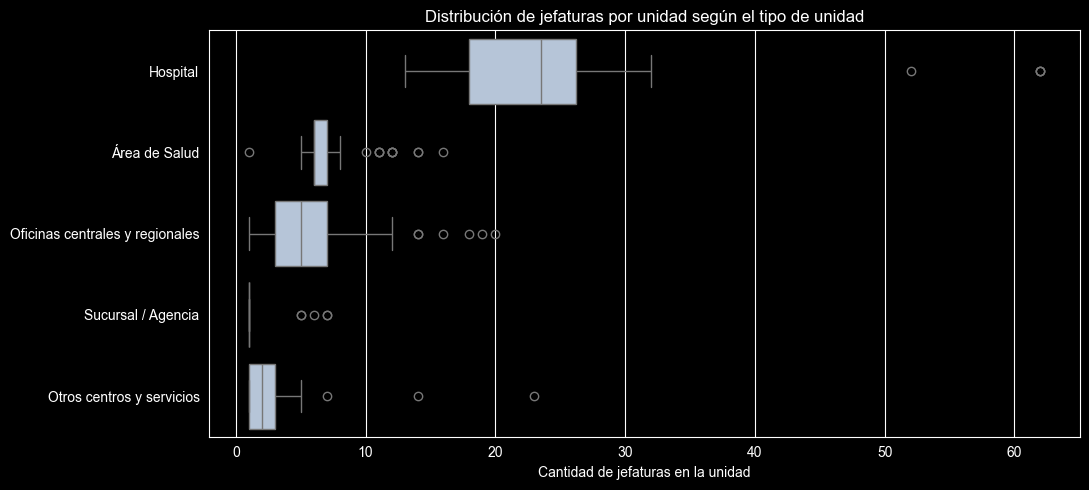

In [141]:
jefaturas_tipo = (
    df.groupby([tipos.rename("tipo_unidad"), df["Detalle de UP"]])
    .size()
    .reset_index(name="jefaturas")
)

print(jefaturas_tipo.groupby("tipo_unidad")["jefaturas"].describe().round(2))

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=jefaturas_tipo,
    x="jefaturas",
    y="tipo_unidad",
    order=orden,
    color="lightsteelblue"
)
plt.title("Distribución de jefaturas por unidad según el tipo de unidad")
plt.xlabel("Cantidad de jefaturas en la unidad")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [142]:
areas = jefaturas_tipo[jefaturas_tipo["tipo_unidad"] == "Área de Salud"]
print(
    "Áreas de salud con 6 o 7 jefaturas:",
    areas["jefaturas"].between(6, 7).sum(), "de", len(areas)
)

unipersonales = jefaturas_tipo[jefaturas_tipo["jefaturas"] == 1]
print("\nUnidades con una sola jefatura según su tipo:")
print(unipersonales["tipo_unidad"].value_counts().to_dict())

Áreas de salud con 6 o 7 jefaturas: 75 de 99

Unidades con una sola jefatura según su tipo:
{'Sucursal / Agencia': 73, 'Otros centros y servicios': 8, 'Oficinas centrales y regionales': 7, 'Área de Salud': 1}


### Interpretación de la distribución por tipo de unidad

Las áreas de salud presentan una estructura muy estandarizada: 75 de las 99 tienen exactamente 6 o 7 jefaturas, con una dispersión baja (desviación estándar de 2.15). Sus puestos más comunes (registros de salud, administración, enfermería, medicina, trabajo social, microbiología y farmacia) sugieren un modelo organizativo común para el primer nivel de atención.

Los hospitales son las unidades más grandes y las más heterogéneas: van de 13 a 62 jefaturas.

De las 89 unidades con una sola jefatura, 73 son sucursales o agencias, lo que confirma que este tipo de unidad se dirige normalmente con una única jefatura administrativa.

Las oficinas centrales y regionales y los otros centros muestran estructuras pequeñas o medianas con mayor variabilidad.

Estos patrones sugieren que existen perfiles naturales de unidades, lo que respalda el uso de
técnicas de agrupamiento.

### Distribución de jefaturas por unidad

In [143]:
jefaturas_por_unidad = (
    df.groupby(
        ["Unidad de procedencia (UP)", "Detalle de UP"]
    )
    .size()
    .reset_index(name="Cantidad de jefaturas")
    .sort_values("Cantidad de jefaturas", ascending=False)
)

jefaturas_por_unidad.head(20)

,Unidad de procedencia (UP),Detalle de UP,Cantidad de jefaturas
110,2102,Hospital San Juan de Dios,62
112,2104,Hospital México,62
111,2103,Hospital Nacional de Niños Carlos Saenz Herrera,62
109,2101,Hospital Rafael Ángel Calderón Guardia,52
150,2306,Hospital Maximiliano Peralta Jiménez,32
232,2701,Hospital Fernando Escalante Pradilla,28
118,2207,Hospital Carlos Luis Valverde Vega,27
119,2208,Hospital San Vicente de Paul,26
116,2205,Hospital de San Rafael,25
148,2304,Hospital Nacional Psiquiátrico Manuel Antonio Chapuí y Torres,25


In [144]:
jefaturas_por_unidad["Cantidad de jefaturas"].describe()

count    284.000000
mean       6.862676
std        8.742820
min        1.000000
25%        1.000000
50%        6.000000
75%        7.000000
max       62.000000
Name: Cantidad de jefaturas, dtype: float64

In [145]:
print(
    "Unidades con una sola jefatura:",
    (jefaturas_por_unidad["Cantidad de jefaturas"] == 1).sum()
)

print(
    "Máximo de jefaturas en una unidad:",
    jefaturas_por_unidad["Cantidad de jefaturas"].max()
)

print(
    "Promedio:",
    round(jefaturas_por_unidad["Cantidad de jefaturas"].mean(), 2)
)

print(
    "Mediana:",
    jefaturas_por_unidad["Cantidad de jefaturas"].median()
)

Unidades con una sola jefatura: 89
Máximo de jefaturas en una unidad: 62
Promedio: 6.86
Mediana: 6.0


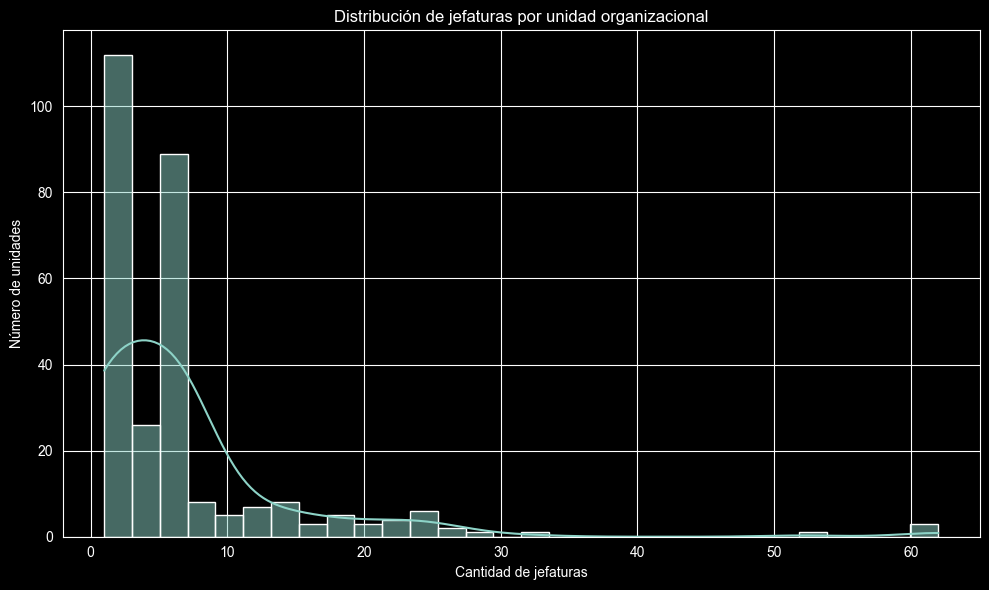

In [146]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=jefaturas_por_unidad,
    x="Cantidad de jefaturas",
    bins=30,
    kde=True
)

plt.title("Distribución de jefaturas por unidad organizacional")
plt.xlabel("Cantidad de jefaturas")
plt.ylabel("Número de unidades")
plt.tight_layout()
plt.show()

### Interpretación de la distribución de jefaturas por unidad

Las 1,949 jefaturas se distribuyen entre 284 unidades organizacionales. La
cantidad promedio es de 6.86 jefaturas por unidad, mientras que la mediana
es de 6. La desviación estándar, de 8.74, evidencia una variabilidad
considerable entre las unidades.

El primer cuartil es igual a 1, lo cual indica que al menos el 25 % de las
unidades presenta solamente una jefatura. Por su parte, el tercer cuartil
es igual a 7, por lo que el 75 % de las unidades tiene 7 jefaturas o menos.
No obstante, el valor máximo alcanza las 62 jefaturas.

El histograma presenta una distribución marcadamente asimétrica hacia la
derecha. La mayor parte de las unidades se concentra en valores bajos,
mientras que un grupo reducido presenta cantidades considerablemente
mayores.

Las unidades con mayor cantidad de jefaturas corresponden principalmente
a hospitales. El Hospital San Juan de Dios, el Hospital México y el
Hospital Nacional de Niños Carlos Sáenz Herrera registran 62 jefaturas
cada uno. Estos resultados pueden relacionarse con el tamaño y la
complejidad operativa de dichas instituciones.

Las diferencias observadas respaldan la aplicación de técnicas de
clusterización para identificar perfiles de unidades según su estructura
de jefaturas. Sin embargo, la elevada asimetría implica que la cantidad
total no debe utilizarse sin tratamiento previo, ya que podría dominar el
cálculo de las distancias. Será necesario evaluar la estandarización y,
posiblemente, una transformación logarítmica de esta variable.

In [147]:
q1 = jefaturas_por_unidad["Cantidad de jefaturas"].quantile(0.25)
q3 = jefaturas_por_unidad["Cantidad de jefaturas"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

posibles_atipicos = jefaturas_por_unidad[
    jefaturas_por_unidad["Cantidad de jefaturas"] > limite_superior
].copy()

print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"Rango intercuartílico: {iqr}")
print(f"Límite superior: {limite_superior}")
print(f"Unidades sobre el límite: {len(posibles_atipicos)}")

posibles_atipicos

Q1: 1.0
Q3: 7.0
Rango intercuartílico: 6.0
Límite superior: 16.0
Unidades sobre el límite: 27


,Unidad de procedencia (UP),Detalle de UP,Cantidad de jefaturas
110,2102,Hospital San Juan de Dios,62
112,2104,Hospital México,62
111,2103,Hospital Nacional de Niños Carlos Saenz Herrera,62
109,2101,Hospital Rafael Ángel Calderón Guardia,52
150,2306,Hospital Maximiliano Peralta Jiménez,32
232,2701,Hospital Fernando Escalante Pradilla,28
118,2207,Hospital Carlos Luis Valverde Vega,27
119,2208,Hospital San Vicente de Paul,26
116,2205,Hospital de San Rafael,25
148,2304,Hospital Nacional Psiquiátrico Manuel Antonio Chapuí y Torres,25


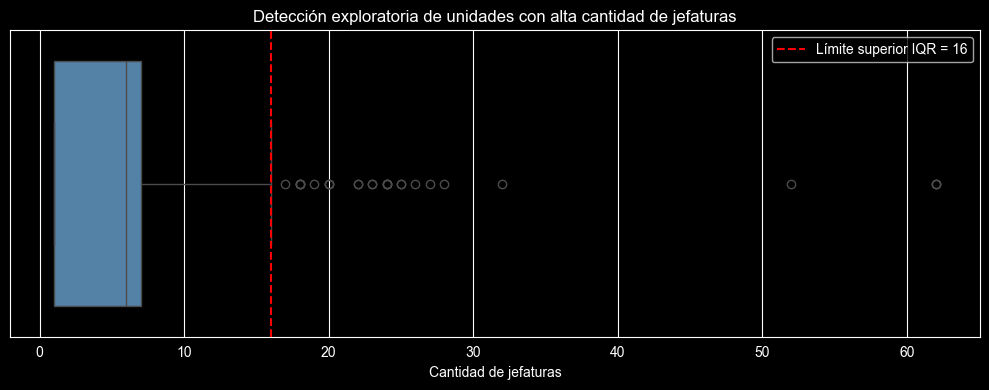

In [148]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=jefaturas_por_unidad,
    x="Cantidad de jefaturas",
    color="steelblue"
)

plt.axvline(
    limite_superior,
    color="red",
    linestyle="--",
    label=f"Límite superior IQR = {limite_superior:.0f}"
)

plt.title("Detección exploratoria de unidades con alta cantidad de jefaturas")
plt.xlabel("Cantidad de jefaturas")
plt.legend()
plt.tight_layout()
plt.show()

In [149]:
rangos_unidades = pd.cut(
    jefaturas_por_unidad["Cantidad de jefaturas"],
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=[
        "1 jefatura",
        "2 a 5",
        "6 a 10",
        "11 a 20",
        "Más de 20"
    ]
)

distribucion_rangos = (
    rangos_unidades
    .value_counts()
    .sort_index()
    .to_frame("Número de unidades")
)

distribucion_rangos["Porcentaje"] = (
    distribucion_rangos["Número de unidades"]
    / len(jefaturas_por_unidad)
    * 100
).round(2)

distribucion_rangos

,Número de unidades,Porcentaje
Cantidad de jefaturas,,
1 jefatura,89,31.34
2 a 5,49,17.25
6 a 10,99,34.86
11 a 20,29,10.21
Más de 20,18,6.34


### Distribución de las unidades según su tamaño

La clasificación por rangos confirma que la estructura organizacional está
compuesta principalmente por unidades pequeñas o medianas. De las 284
unidades analizadas, 89 presentan una única jefatura, lo que representa
el 31.34 % del total.

En conjunto, el 48.59 % de las unidades tiene entre una y cinco jefaturas,
mientras que el 83.45 % posee diez jefaturas o menos. Por el contrario,
solo 47 unidades, equivalentes al 16.55 %, tienen más de diez jefaturas.
Únicamente 18 unidades, correspondientes al 6.34 %, superan las veinte.

El diagrama de caja confirma la asimetría positiva observada en el
histograma. La mayor parte de las unidades se concentra en valores bajos,
mientras que 27 unidades superan el límite superior de 16 jefaturas
calculado mediante el criterio del rango intercuartílico.

Estas observaciones no serán eliminadas, debido a que corresponden a
unidades reales y pueden representar estructuras organizacionales de mayor
tamaño y complejidad. No obstante, la alta dispersión confirma la necesidad
de estandarizar las variables antes del modelado y evaluar una transformación
logarítmica para la cantidad total de jefaturas.

### Diversidad y concentración de puestos

In [150]:
perfil_unidades = (
    df.groupby(
        ["Unidad de procedencia (UP)", "Detalle de UP"]
    )
    .agg(
        total_jefaturas=("Cedula", "count"),
        personas_unicas=("Cedula", "nunique"),
        puestos_distintos=("Puesto", "nunique")
    )
    .reset_index()
)

perfil_unidades.head(10)

,Unidad de procedencia (UP),Detalle de UP,total_jefaturas,personas_unicas,puestos_distintos
0,1100,Gerencia General,1,1,1
1,1101,Junta Directiva,2,2,2
2,1102,Presidencia Ejecutiva,1,1,1
3,1103,Gerencia Financiera,3,3,3
4,1104,Gerencia Administrativa,3,3,3
5,1105,Centro para la Instruccion de Procedimientos Administrativos,1,1,1
6,1106,Gerencia Logística,4,4,3
7,1107,Gerencia Infraestructura y Tecnologías,3,3,3
8,1111,Auditoria Interna,14,14,3
9,1112,Dirección Técnica Actuarial y Económica,6,6,3


In [151]:
diferencias_personas = (
    perfil_unidades["total_jefaturas"]
    != perfil_unidades["personas_unicas"]
).sum()

print(
    "Unidades con diferencia entre total de jefaturas y personas únicas:",
    diferencias_personas
)

Unidades con diferencia entre total de jefaturas y personas únicas: 0


In [152]:
perfil_unidades = perfil_unidades.drop(
    columns="personas_unicas"
)

In [153]:
puesto_principal = (
    df.groupby(
        ["Unidad de procedencia (UP)", "Detalle de UP"]
    )["Puesto"]
    .agg(
        puesto_mas_frecuente=lambda serie: (
            serie.value_counts().index[0]
        ),
        frecuencia_puesto_principal=lambda serie: (
            serie.value_counts().iloc[0]
        )
    )
    .reset_index()
)

perfil_unidades = perfil_unidades.merge(
    puesto_principal,
    on=["Unidad de procedencia (UP)", "Detalle de UP"],
    how="left"
)

In [154]:
perfil_unidades["proporcion_puesto_principal"] = (
    perfil_unidades["frecuencia_puesto_principal"]
    / perfil_unidades["total_jefaturas"]
)

perfil_unidades["proporcion_diversidad"] = (
    perfil_unidades["puestos_distintos"]
    / perfil_unidades["total_jefaturas"]
)

perfil_unidades.head(10)

,Unidad de procedencia (UP),Detalle de UP,total_jefaturas,puestos_distintos,puesto_mas_frecuente,frecuencia_puesto_principal,proporcion_puesto_principal,proporcion_diversidad
0,1100,Gerencia General,1,1,Jefe Despacho Gerencia General,1,1.000000,1.000000
1,1101,Junta Directiva,2,2,Jefe Subárea de Sede,1,0.500000,1.000000
2,1102,Presidencia Ejecutiva,1,1,Asesor Coordinar Presidencia Ejecutiva,1,1.000000,1.000000
3,1103,Gerencia Financiera,3,3,Jefe Área de Sede,1,0.333333,1.000000
4,1104,Gerencia Administrativa,3,3,Jefe Centro de Gestión Informatica Gerencial,1,0.333333,1.000000
5,1105,Centro para la Instruccion de Procedimientos Administrativos,1,1,Director Institucional de Sede,1,1.000000,1.000000
6,1106,Gerencia Logística,4,3,Jefe Área de Sede,2,0.500000,0.750000
7,1107,Gerencia Infraestructura y Tecnologías,3,3,Jefe Área de Sede,1,0.333333,1.000000
8,1111,Auditoria Interna,14,3,Jefe Subárea de Sede,8,0.571429,0.214286
9,1112,Dirección Técnica Actuarial y Económica,6,3,Jefe Área de Sede,4,0.666667,0.500000


In [155]:
variables_perfil = [
    "total_jefaturas",
    "puestos_distintos",
    "frecuencia_puesto_principal",
    "proporcion_puesto_principal",
    "proporcion_diversidad"
]

perfil_unidades[
    variables_perfil
].describe().round(3)

,total_jefaturas,puestos_distintos,frecuencia_puesto_principal,proporcion_puesto_principal,proporcion_diversidad
count,284.000,284.000,284.000,284.000,284.000
mean,6.863,5.401,2.099,0.502,0.909
std,8.743,5.265,3.565,0.369,0.189
min,1.000,1.000,1.000,0.067,0.200
25%,1.000,1.000,1.000,0.167,0.944
50%,6.000,4.000,1.000,0.414,1.000
75%,7.000,7.000,2.000,1.000,1.000
max,62.000,25.000,31.000,1.000,1.000


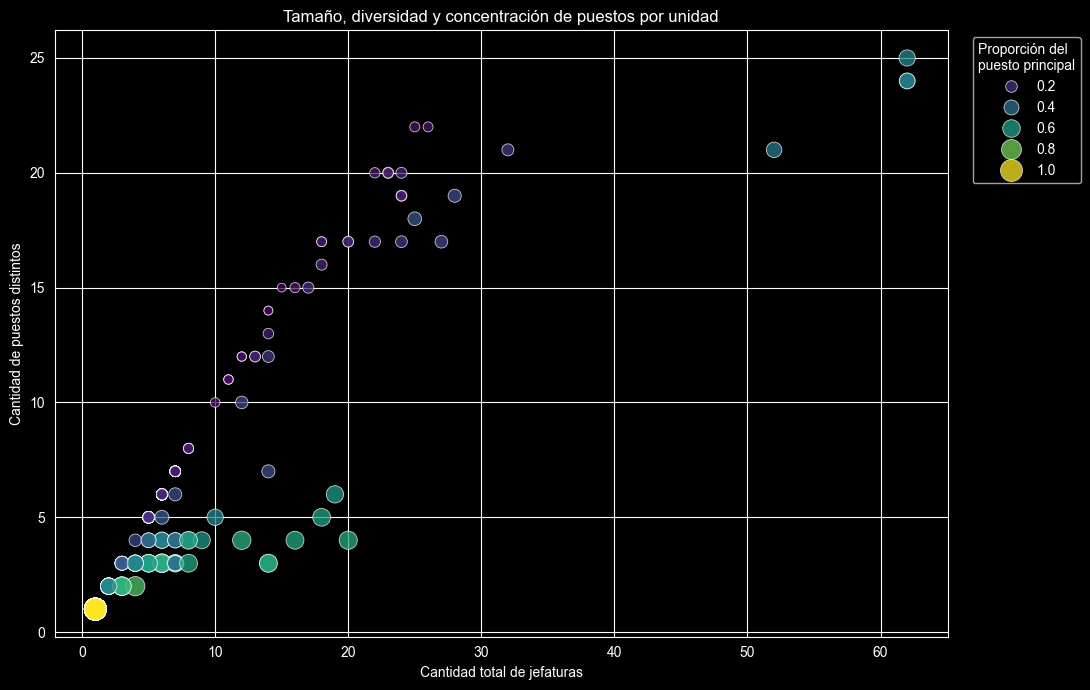

In [156]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=perfil_unidades,
    x="total_jefaturas",
    y="puestos_distintos",
    size="proporcion_puesto_principal",
    hue="proporcion_puesto_principal",
    palette="viridis",
    sizes=(40, 250),
    alpha=0.75
)

plt.title(
    "Tamaño, diversidad y concentración de puestos por unidad"
)
plt.xlabel("Cantidad total de jefaturas")
plt.ylabel("Cantidad de puestos distintos")

plt.legend(
    title="Proporción del\npuesto principal",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Análisis del tamaño, diversidad y concentración de puestos

Al agregar los datos a nivel de unidad organizacional se comprobó que el
número total de jefaturas coincide con el número de personas únicas en las
284 unidades. Por lo tanto, la variable personas_unicas no aporta
información adicional y puede excluirse del conjunto de características.

La cantidad de puestos distintos presenta una media de 5.40 puestos por
unidad y alcanza un máximo de 25. Esto evidencia diferencias importantes
en la complejidad y variedad de las estructuras de jefatura.

La proporción correspondiente al puesto más frecuente presenta una media
de 0.502 y una mediana de 0.414. En términos generales, aproximadamente la
mitad de las jefaturas de una unidad pertenecen, en promedio, al tipo de
puesto predominante. Sin embargo, este promedio está influido por las 89 unidades con una
sola jefatura, en las que la proporción es igual a 1; por eso la mediana
(0.414) representa mejor a una unidad típica. Además, existe una
variabilidad considerable entre unidades.

El gráfico de dispersión evidencia una relación positiva entre la cantidad
total de jefaturas y la cantidad de puestos distintos: las unidades de
mayor tamaño tienden a presentar mayor variedad de puestos. No obstante,
la relación no es perfecta. Existen unidades con cantidades similares de
jefaturas y niveles diferentes de diversidad y concentración.

Este comportamiento indica que utilizar únicamente el tamaño de la unidad
sería insuficiente para caracterizar su estructura. Por ello, el modelado
considerará conjuntamente indicadores de tamaño, diversidad y concentración.

### Correlación

In [157]:
variables_analisis = [
    "total_jefaturas",
    "puestos_distintos",
    "frecuencia_puesto_principal",
    "proporcion_puesto_principal",
    "proporcion_diversidad"
]

correlaciones = (
    perfil_unidades[variables_analisis]
    .corr()
    .round(3)
)

correlaciones

,total_jefaturas,puestos_distintos,frecuencia_puesto_principal,proporcion_puesto_principal,proporcion_diversidad
total_jefaturas,1.000,0.880,0.844,-0.420,-0.508
puestos_distintos,0.880,1.000,0.493,-0.656,-0.217
frecuencia_puesto_principal,0.844,0.493,1.000,-0.038,-0.688
proporcion_puesto_principal,-0.420,-0.656,-0.038,1.000,0.010
proporcion_diversidad,-0.508,-0.217,-0.688,0.010,1.000


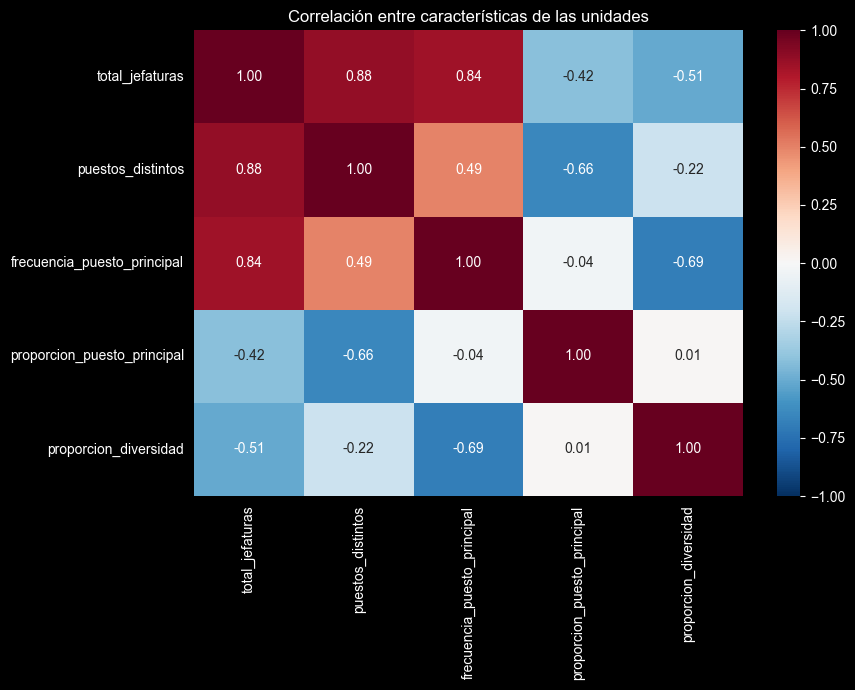

In [158]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre características de las unidades")
plt.tight_layout()
plt.show()

In [159]:
from scipy.stats import entropy

def calcular_entropia_puestos(serie):
    proporciones = serie.value_counts(normalize=True)
    return entropy(proporciones)

entropia_unidades = (
    df.groupby(
        ["Unidad de procedencia (UP)", "Detalle de UP"]
    )["Puesto"]
    .apply(calcular_entropia_puestos)
    .reset_index(name="entropia_puestos")
)

perfil_unidades = perfil_unidades.merge(
    entropia_unidades,
    on=["Unidad de procedencia (UP)", "Detalle de UP"],
    how="left"
)

In [160]:
perfil_unidades["entropia_puestos"].describe().round(3)

count    284.000
mean       1.186
std        0.951
min        0.000
25%        0.000
50%        1.271
75%        1.946
max        3.032
Name: entropia_puestos, dtype: float64

In [161]:
perfil_unidades.sort_values(
    "entropia_puestos",
    ascending=False
)[[
    "Unidad de procedencia (UP)",
    "Detalle de UP",
    "total_jefaturas",
    "puestos_distintos",
    "proporcion_puesto_principal",
    "entropia_puestos"
]].head(20)

,Unidad de procedencia (UP),Detalle de UP,total_jefaturas,puestos_distintos,proporcion_puesto_principal,entropia_puestos
148,2304,Hospital Nacional Psiquiátrico Manuel Antonio Chapuí y Torres,25,22,0.120000,3.031591
119,2208,Hospital San Vicente de Paul,26,22,0.115385,3.024696
117,2206,Hospital San Francisco de Asís,22,20,0.136364,2.941232
151,2307,Hospital William Allen Taylor,23,20,0.130435,2.931923
115,2203,Centro Nacional de Rehabilitación Humberto Araya Rojas,23,20,0.173913,2.894400
220,2601,Hospital Tony Facio Castro,24,20,0.166667,2.889243
190,2502,Hospital Enrique Baltodano Briceño,24,19,0.125000,2.867440
189,2501,Hospital Víctor Manuel Sanabria Martínez,24,19,0.166667,2.831480
235,2704,Hospital de Ciudad Neily,18,17,0.111111,2.813355
236,2705,Hospital de San Vito,18,17,0.111111,2.813355


### Correlación y diversidad estructural de las unidades

El análisis de correlación evidencia una asociación positiva elevada entre
la cantidad total de jefaturas y la cantidad de puestos distintos
(r = 0.880). También existe una correlación elevada entre el total de
jefaturas y la frecuencia absoluta del puesto principal (r = 0.844).

Estos resultados indican que algunas características contienen información
parcialmente redundante relacionada con el tamaño de la unidad. Incluir
simultáneamente todas estas variables en un algoritmo basado en distancia,
como K-Means, podría otorgar un peso excesivo a esta dimensión.

Por otra parte, los indicadores relativos permiten analizar características
diferentes. La proporción del puesto principal presenta una correlación
negativa de -0.656 con la cantidad de puestos distintos, lo que indica que
las unidades con mayor variedad de puestos tienden a presentar una menor
concentración en una única categoría.

Como indicador adicional de diversidad se calculó la entropía de Shannon
sobre la distribución de puestos de cada unidad. La entropía presenta una
media de 1.186, una mediana de 1.271 y un máximo de 3.032. Las unidades que
presentan un único tipo de puesto obtienen una entropía igual a cero,
mientras que valores mayores representan estructuras con puestos más
diversos y distribuidos de forma más equilibrada.

Este indicador permite diferenciar entre tamaño y diversidad estructural.
Por ejemplo, una unidad puede contener numerosas jefaturas concentradas en
pocos tipos de puestos, mientras otra de tamaño similar puede distribuirlas
entre una mayor variedad de funciones.

Por este motivo, la selección de características para el modelado evitará
incorporar variables altamente redundantes y buscará representar tres
dimensiones principales: tamaño de la unidad, diversidad de puestos y
concentración de su estructura.

### Distribución de las variables construidas por unidad

Además del total de jefaturas, se analizan la forma de la distribución de todas las variables
construidas por unidad: histograma, diagrama de caja y medidas de forma (asimetría y curtosis).

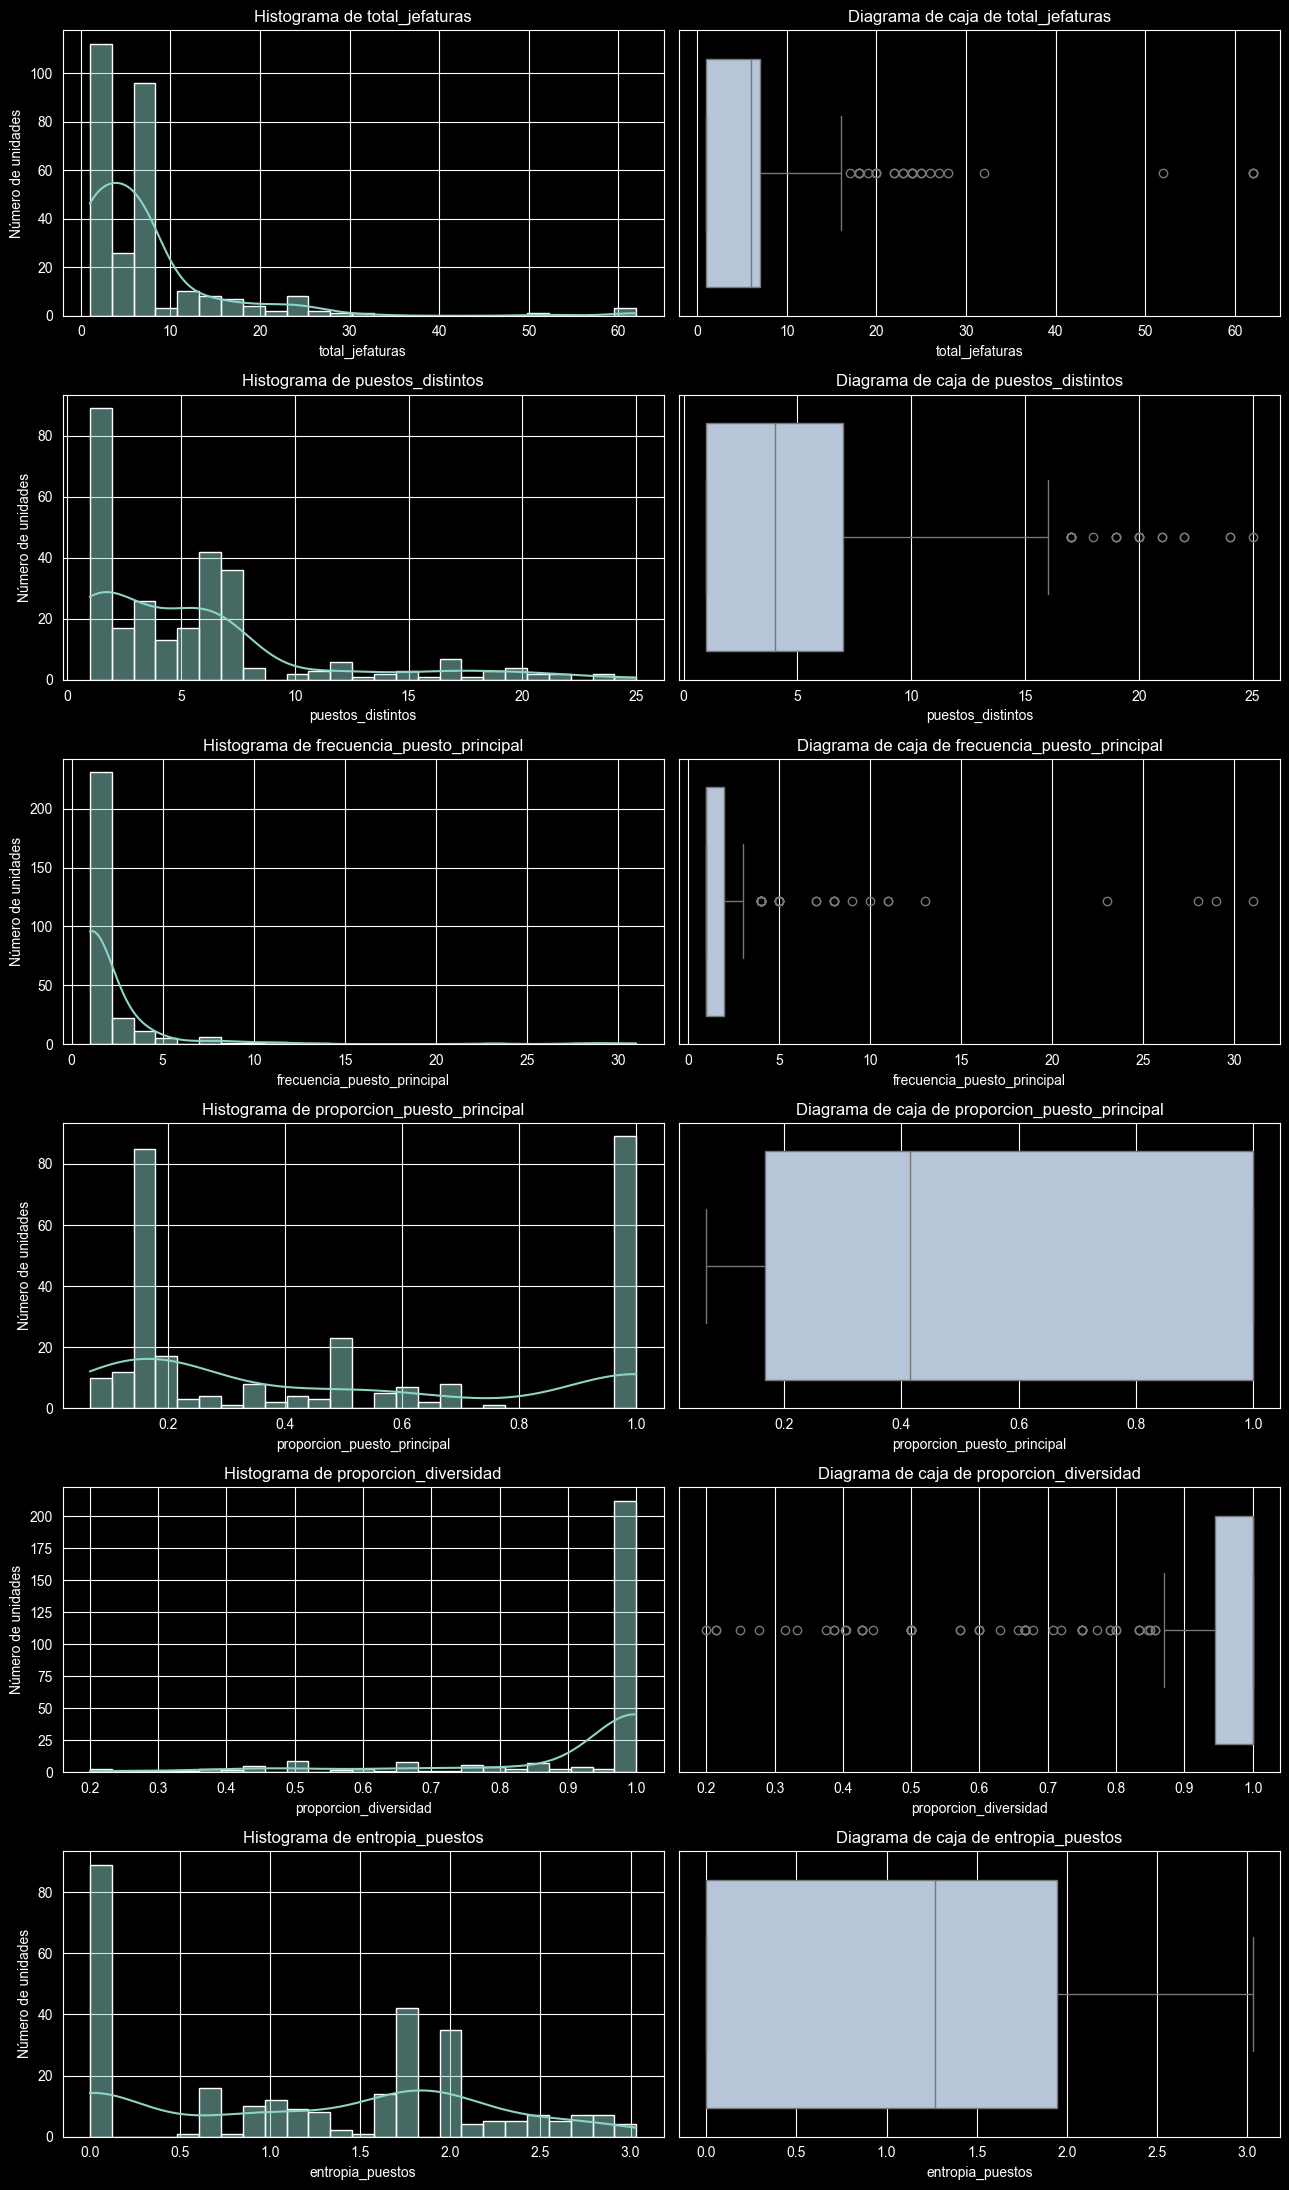

In [162]:
variables_distribucion = [
    "total_jefaturas",
    "puestos_distintos",
    "frecuencia_puesto_principal",
    "proporcion_puesto_principal",
    "proporcion_diversidad",
    "entropia_puestos"
]

fig, axes = plt.subplots(len(variables_distribucion), 2, figsize=(13, 22))

for fila, variable in enumerate(variables_distribucion):
    sns.histplot(perfil_unidades[variable], bins=25, kde=True, ax=axes[fila, 0])
    axes[fila, 0].set_title(f"Histograma de {variable}")
    axes[fila, 0].set_xlabel(variable)
    axes[fila, 0].set_ylabel("Número de unidades")

    sns.boxplot(x=perfil_unidades[variable], color="lightsteelblue", ax=axes[fila, 1])
    axes[fila, 1].set_title(f"Diagrama de caja de {variable}")
    axes[fila, 1].set_xlabel(variable)

plt.tight_layout()
plt.show()

In [163]:
forma_distribucion = pd.DataFrame({
    "Asimetría": perfil_unidades[variables_distribucion].skew(),
    "Curtosis": perfil_unidades[variables_distribucion].kurt()
}).round(3)

forma_distribucion

,Asimetría,Curtosis
total_jefaturas,3.641,17.922
puestos_distintos,1.697,2.592
frecuencia_puesto_principal,5.861,39.457
proporcion_puesto_principal,0.389,-1.577
proporcion_diversidad,-2.112,3.422
entropia_puestos,0.011,-1.317


In [164]:
print(
    "Unidades con proporcion_diversidad igual a 1:",
    round((perfil_unidades["proporcion_diversidad"] == 1).mean() * 100, 2), "%"
)
print(
    "Unidades con entropía igual a 0:",
    (perfil_unidades["entropia_puestos"] == 0).sum()
)

Unidades con proporcion_diversidad igual a 1: 74.65 %
Unidades con entropía igual a 0: 89


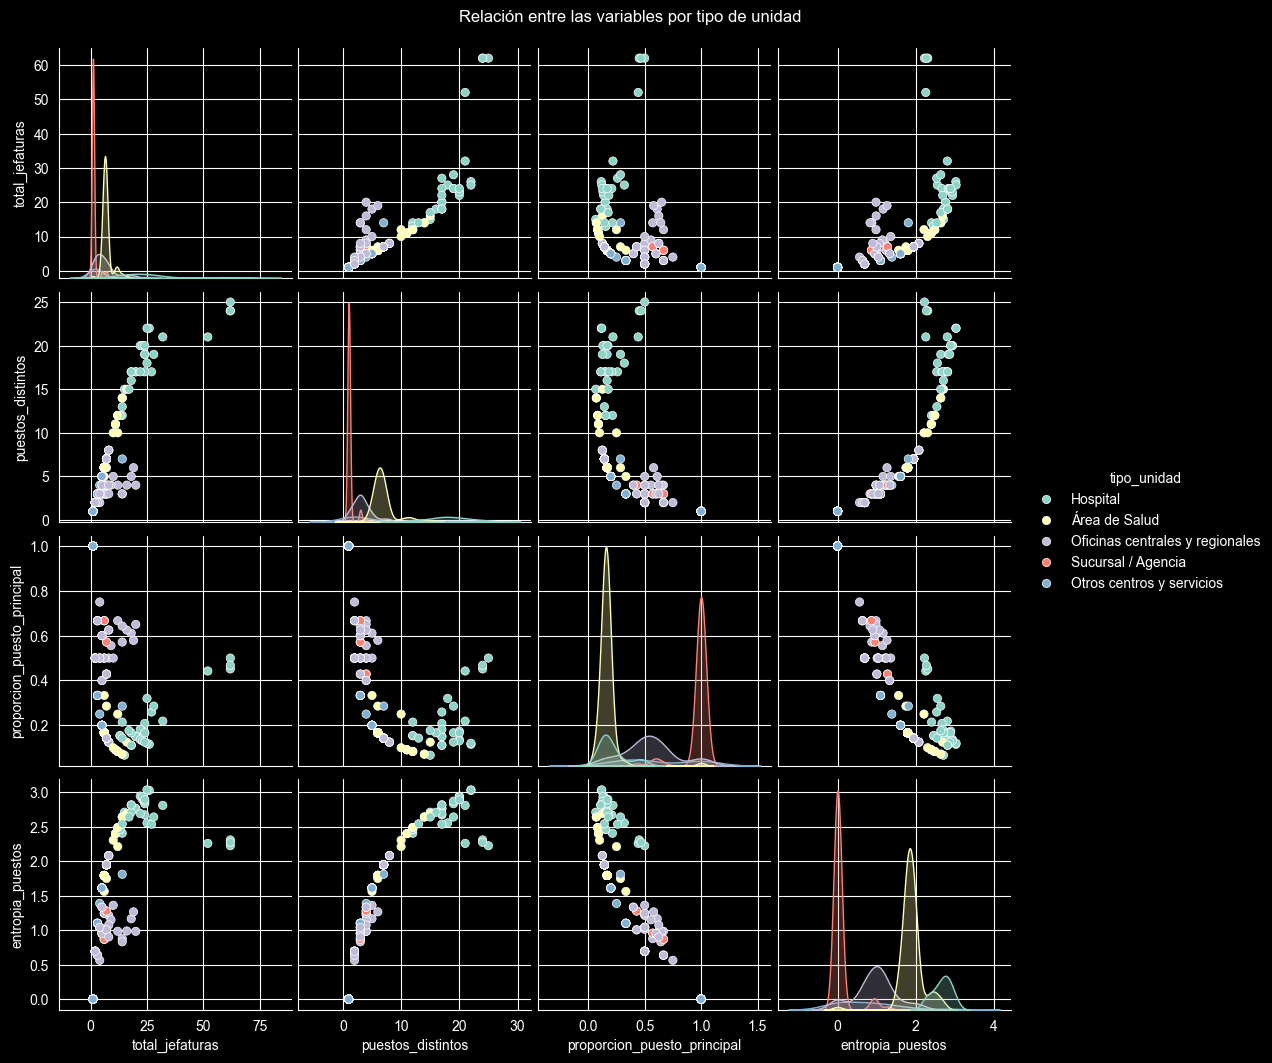

In [165]:
perfil_unidades["tipo_unidad"] = perfil_unidades["Detalle de UP"].apply(tipo_unidad)

sns.pairplot(
    perfil_unidades,
    vars=[
        "total_jefaturas",
        "puestos_distintos",
        "proporcion_puesto_principal",
        "entropia_puestos"
    ],
    hue="tipo_unidad",
    hue_order=orden,
    height=2.6
)

plt.suptitle("Relación entre las variables por tipo de unidad", y=1.02)
plt.show()

### Interpretación de la distribución de las variables

total_jefaturas y frecuencia_puesto_principal presentan una asimetría positiva muy fuerte (3.64 y 5.86) y una curtosis elevada (17.92 y 39.46): la mayoría de las unidades tiene valores bajos y unas pocas, principalmente hospitales, tienen valores extremos. Esto confirma la necesidad de una transformación logarítmica antes del modelado.

puestos_distintos también es asimétrica hacia la derecha (1.70), aunque de forma moderada.

proporcion_diversidad tiene asimetría negativa (-2.11): el 74.65 % de las unidades tiene un valor de 1, es decir, todas sus jefaturas ocupan puestos diferentes. Como esta variable toma casi siempre el mismo valor, aporta poca capacidad para diferenciar unidades.

proporcion_puesto_principal y entropia_puestos tienen una curtosis negativa (-1.58 y -1.32), lo que indica distribuciones aplanadas y con varios grupos de valores. En ambas sobresale un bloque de 89 unidades (31.34 %) con valores extremos (proporción igual a 1 y entropía igual a 0), que corresponde a las unidades con una sola jefatura.

El gráfico de pares muestra que los tipos de unidad ocupan zonas distintas del espacio de las variables: las sucursales se concentran en el extremo de una sola jefatura, las áreas de salud forman un núcleo compacto de unidades medianas y diversificadas, y los hospitales se separan por su tamaño y su alta entropía. Esta separación visual apoya las hipótesis de agrupamiento planteadas al final de esta fase.

## 2.4 Verificación de la calidad de los datos

En esta tarea se verifica la completitud y la corrección de los datos: la cantidad de valores nulos,
la existencia de duplicados, la consistencia de los valores de cada campo y la presencia de valores
inválidos o fuera de formato que puedan constituir ruido para el proceso.

La completitud ya se verificó en la descripción de los datos: no existen valores nulos en
ninguna de las seis variables.

### Duplicados y nombres repetidos

In [166]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("Cédulas duplicadas:", df["Cedula"].duplicated().sum())
print("Nombres duplicados:", df["Nombre"].duplicated().sum())

Filas completamente duplicadas: 0
Cédulas duplicadas: 0
Nombres duplicados: 1


In [167]:
nombres_repetidos = df[
    df["Nombre"].duplicated(keep=False)
].sort_values("Nombre")

nombres_repetidos

,Cedula,Nombre,Unidad de procedencia (UP),Detalle de UP,Puesto,Fecha de actualización
96,107900729,JOHNNY MORA QUESADA,1128,Dirección Inspección,Jefe Subárea de Sede,2026-10-12 00:00:00
98,106650890,JOHNNY MORA QUESADA,1128,Dirección Inspección,Jefe Subárea de Sede,2026-10-12 00:00:00


In [168]:
detalles_por_codigo = (
    df.groupby("Unidad de procedencia (UP)")["Detalle de UP"]
      .nunique()
      .sort_values(ascending=False)
)

codigos_por_detalle = (
    df.groupby("Detalle de UP")["Unidad de procedencia (UP)"]
      .nunique()
      .sort_values(ascending=False)
)

print(
    "Códigos asociados con más de un detalle:",
    (detalles_por_codigo > 1).sum()
)

print(
    "Detalles asociados con más de un código:",
    (codigos_por_detalle > 1).sum()
)

Códigos asociados con más de un detalle: 0
Detalles asociados con más de un código: 0


In [169]:
df["Fecha de actualización"].value_counts(dropna=False)

Fecha de actualización
2026-10-12 00:00:00    1949
Name: count, dtype: int64

### Análisis de duplicados y consistencia de identificadores

No se identificaron filas completamente duplicadas ni cédulas repetidas en
el conjunto de datos. Por lo tanto, los 1,949 registros corresponden a
identificadores individuales diferentes.

Se detectó un único nombre repetido: JOHNNY MORA QUESADA. Sin embargo,
los dos registros presentan números de cédula diferentes. Ambos pertenecen
a la unidad 1128, Dirección Inspección, y registran el puesto
Jefe Subárea de Sede.

Debido a que la cédula funciona como identificador individual y los valores
son diferentes, no existe evidencia suficiente para considerar estos
registros como duplicados. En consecuencia, ambos registros se conservarán
en el conjunto de datos.

También se verificó la correspondencia entre Unidad de procedencia (UP)
y Detalle de UP. No existen códigos asociados con más de un detalle ni
detalles asociados con más de un código. Esto confirma, dentro del conjunto
de datos analizado, una relación uno a uno entre el código de la unidad y
su descripción.

Finalmente, los 1,949 registros presentan la misma fecha de actualización:
12 de octubre de 2026. La variable representa, por lo tanto, la fecha de
corte del conjunto de datos y no aporta variabilidad para el proceso de
clusterización. Se conservará como información descriptiva, pero no será
utilizada como característica del modelo.

### Calidad de los campos de texto

Se revisa si los textos presentan espacios al inicio o al final, espacios dobles, valores
inválidos (como #N/D) o variantes de escritura que pudieran generar categorías duplicadas.

In [170]:
for columna in ["Nombre", "Detalle de UP", "Puesto"]:
    texto = df[columna]
    sin_espacios_extra = texto.str.strip().str.replace(r"\s+", " ", regex=True)

    print(columna)
    print("  Con espacios al inicio o al final:", (texto != texto.str.strip()).sum())
    print("  Con espacios dobles:", texto.str.strip().str.contains("  ").sum())
    print("  Valores únicos originales:", texto.nunique())
    print("  Valores únicos sin espacios extra:", sin_espacios_extra.nunique())
    print("  Valores únicos sin espacios extra y en minúsculas:", sin_espacios_extra.str.lower().nunique())
    print()

Nombre
  Con espacios al inicio o al final: 14
  Con espacios dobles: 15
  Valores únicos originales: 1948
  Valores únicos sin espacios extra: 1948
  Valores únicos sin espacios extra y en minúsculas: 1948

Detalle de UP
  Con espacios al inicio o al final: 0
  Con espacios dobles: 0
  Valores únicos originales: 284
  Valores únicos sin espacios extra: 284
  Valores únicos sin espacios extra y en minúsculas: 284

Puesto
  Con espacios al inicio o al final: 30
  Con espacios dobles: 243
  Valores únicos originales: 159
  Valores únicos sin espacios extra: 159
  Valores únicos sin espacios extra y en minúsculas: 159



In [171]:
valores_invalidos = df[df["Puesto"] == "#N/D"]

print("Registros con Puesto = #N/D:", len(valores_invalidos))
valores_invalidos

Registros con Puesto = #N/D: 1


,Cedula,Nombre,Unidad de procedencia (UP),Detalle de UP,Puesto,Fecha de actualización
1739,603480987,JUAN CARLOS ANCHIA ANGULO,2703,Hospital de Osa Tomás Casas Casajús,#N/D,2026-10-12 00:00:00


In [172]:
puestos_con_espacios = df.loc[
    df["Puesto"].str.contains("  ") | (df["Puesto"] != df["Puesto"].str.strip()),
    "Puesto"
].unique()

print("Algunos puestos con espacios irregulares (entre corchetes para que se vean los espacios):")
for puesto in puestos_con_espacios[:8]:
    print("[" + puesto + "]")

nombres_con_relleno = df[df["Nombre"].str.contains("     ")]
print()
print("Nombres con relleno de espacios:", len(nombres_con_relleno))

Algunos puestos con espacios irregulares (entre corchetes para que se vean los espacios):
[Jefe Despacho Gerencia General ]
[Director Servicios Informáticos ]
[Director Administrativo Financiero Hosp. Nacional ]
[Enfermera  7   Licenciada]
[Microbiólogo Clínico  5]
[Microbiólogo Clínico  4]
[Odontólogo Jefe Servicio ]
[Profesional 1 en Contabilidad y Finanzas ]

Nombres con relleno de espacios: 14


### Interpretación de la calidad de los textos

Puesto presenta 30 valores con espacios al final y 243 con espacios dobles internos (por ejemplo Enfermera  4   Licenciada). Nombre presenta 14 registros con espacios al final y 15 con espacios dobles; en 14 de ellos el nombre viene rellenado con espacios hasta un ancho fijo, lo que sugiere que esos registros provienen de otro sistema de origen.

Al quitar los espacios extra y pasar el texto a minúsculas, la cantidad de categorías no cambia (159 puestos y 284 unidades). Es decir, las irregularidades de escritura no generan categorías duplicadas en este conjunto de datos. Aun así, deben corregirse para presentar tablas limpias y evitar errores en comparaciones de texto.

Existe 1 registro con el valor inválido #N/D en Puesto (Hospital de Osa Tomás Casas Casajús). Este valor corresponde típicamente a una búsqueda fallida en Excel y no representa un puesto real.

Se observan también inconsistencias menores de escritura: unidades con Area sin tilde frente a Área, puestos como Farmaceutico u Odontologo sin tilde, y abreviaturas como Hosp., Serv. Financ. o (G. de E.).

Las correcciones de espacios y del valor #N/D se aplican en la sección 3, de preparación de los datos.

### Formato de las identificaciones

In [173]:
cedulas = df["Cedula"].astype(str)

print("¿Todas las cédulas tienen solo números?:", cedulas.str.isdigit().all())
print("Cantidad de dígitos:", cedulas.str.len().value_counts().to_dict())

df[cedulas.str.len() != 9][["Cedula", "Detalle de UP", "Puesto"]]

¿Todas las cédulas tienen solo números?: True
Cantidad de dígitos: {9: 1941, 11: 8}


,Cedula,Detalle de UP,Puesto
373,27600061328,Hospital San Juan de Dios,Médico Jefe 3
396,59100032119,Hospital San Juan de Dios,Médico Asistente Especialista en Ginecología
1581,55814964134,Hospital Tony Facio Castro,Jefe de Mantenimiento 1
1714,59100003823,Hospital Manuel Mora Valverde,Enfermera 5 Licenciada
1753,59100146203,Hospital de Ciudad Neily,Jefe Gestión Trabajo Social 3
1809,59100172636,Dirección Red Integrada de Prestación de Servicios de Salud Brunca,Director Regional Servicios Médicos
1811,59100054625,Dirección Red Integrada de Prestación de Servicios de Salud Brunca,Enfermera 7 Licenciada
1868,55802028914,CENDEISSS,Médico Evaluador 2


### Interpretación del formato de las identificaciones

Todas las identificaciones contienen únicamente dígitos. 1,941 registros tienen el formato de
cédula nacional de 9 dígitos y 8 registros tienen 11 dígitos, formato que corresponde
probablemente a documentos de identificación de personas extranjeras. No se trata de un error, sino
de una particularidad de los datos que se documenta. Como la identificación no se utiliza en el
modelo, esta diferencia no afecta el análisis.

## 2.5 Informe de calidad y conclusiones de la comprensión de los datos

| # | Hallazgo | Acción |
|---|---|---|
| 1 | Archivo en latin-1 con separador ; | Leer con encoding="latin-1" y sep=";" |
| 2 | Sin valores nulos, sin filas duplicadas y sin cédulas repetidas | No se requiere imputación ni eliminación de duplicados |
| 3 | Un nombre repetido con cédulas distintas | Se conserva (homónimos) |
| 4 | Relación uno a uno entre código y nombre de unidad (284) | Se puede usar cualquiera de las dos como llave |
| 5 | Fecha de actualización con un único valor | Excluir del modelo |
| 6 | Cedula y Nombre son identificadores | Excluir del modelo |
| 7 | Cedula y código de UP leídos como enteros | Tratarlos como texto o categoría |
| 8 | Espacios irregulares en Puesto (273) y Nombre (29) | Limpiar en la sección 3 |
| 9 | 1 registro con Puesto = #N/D | Eliminar en la sección 3 |
| 10 | 8 identificaciones de 11 dígitos | Se conservan (formato válido) |
| 11 | 33.09 % de puestos sin término de jefatura | Se conservan y se documentan para la interpretación |
| 12 | Alta cardinalidad: 159 puestos (50 únicos) y 284 unidades (89 con un registro) | Construir indicadores por unidad en lugar de usar las categorías directamente |
| 13 | Distribución de jefaturas por unidad muy asimétrica (1 a 62) | Transformación logarítmica y estandarización en el preprocesamiento |
| 14 | Variables de tamaño altamente correlacionadas (r = 0.88) | Evitar variables redundantes en el modelo |

En síntesis, el conjunto de datos presenta una buena calidad estructural: no tiene nulos ni
duplicados y su estructura es consistente. Los problemas encontrados son de formato del texto y
un valor inválido, que se corrigen en la limpieza. El principal reto para el modelado es que no
existen variables numéricas directas, por lo que el análisis se realizará a nivel de unidad
organizacional, construyendo indicadores de tamaño, diversidad y concentración de sus jefaturas.

### Hipótesis iniciales

A partir de la exploración se formulan las siguientes hipótesis, que se contrastarán con los
resultados del modelado:

H1. Las unidades con una sola jefatura, en su mayoría sucursales, formarán un perfil propio claramente separado del resto.

H2. Las áreas de salud, por su estructura estandarizada de 6 a 7 jefaturas, se concentrarán en un mismo perfil de unidades medianas y diversificadas.

H3. Los hospitales de mayor tamaño formarán uno o más perfiles de alta complejidad, con muchas jefaturas y gran variedad de puestos.

H4. El tamaño de una unidad no basta para describir su estructura: unidades de tamaño similar pueden diferir en su diversidad y concentración de puestos.